# 3.1 — Segment baseline & score signal within segments

**Goal**: validate the two assumptions of the segment × cutoff policy: 

(1) the **segment baseline** risk ordering is stable across vintages; 
(2) **`score_klavi_2` orders risk inside each named segment**.
(3) Then make the **missing-score rule** explicit.

**Input**: `data/processed/applications_segmented.parquet` + `bin_spec.yaml` (score bins).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import binning, woe  # noqa: E402  (path set above)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

app = pd.read_parquet(PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet")
bin_spec = binning.load_spec(PROJECT_DIR / "references" / "bin_spec.yaml")

assert app["segmento"].cat.ordered            # segmentation persisted by 3.0
app["score_bin"] = binning.apply_spec(app["score_klavi_2"], bin_spec["score_klavi_2"])

lab = app[app["OVER30M2"].notna()].copy()
y = lab["OVER30M2"].astype(int)

SEGS = list(lab["segmento"].cat.categories)
NAMED = [s for s in SEGS if s != "(missing)"]
C_SEG = dict(zip(SEGS, ["#1c5cab", "#2a78d6", "#86b6ef", "#e34948", "#eb6834", "0.5"]))
C_RISK = "#e34948"
print(f"labeled: {len(lab):,}  |  segments: {SEGS}")

labeled: 24,148  |  segments: ['A/B/C · Desconhecido', 'A/B/C · Autônomo', 'A/B/C · Formal', 'D/E · Desconhecido', 'D/E · Autônomo/Formal', '(missing)']


## 1. Segment baseline — stability across vintages

The 3.0 baseline is only usable if it holds vintage by vintage. WoE per
segment per `SAFRA` (positive = safer than the book average; `woe_over_time` masks bins with
n < 10) plus PSI of the segment mix (each safra vs pooled).

segment-mix PSI vs pooled: max 0.027 (all << 0.10 'stable')


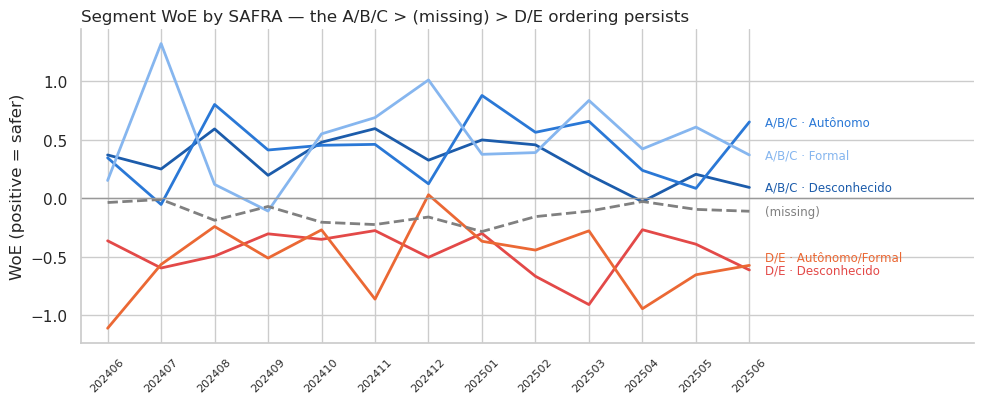

In [2]:
wt = woe.woe_over_time(lab["segmento"], y, lab["SAFRA"])
pooled = lab["segmento"].value_counts()
psi_s = pd.Series({sf: woe.psi(pooled, lab.loc[lab["SAFRA"] == sf, "segmento"].value_counts())
                   for sf in sorted(lab["SAFRA"].unique())})
print(f"segment-mix PSI vs pooled: max {psi_s.max():.3f} (all << 0.10 'stable')")

def spread(vals, gap=0.11):
    """Nudge overlapping right-edge labels apart (keeps order)."""
    out, prev = {}, None
    for k, v in vals.sort_values().items():
        v = v if prev is None else max(v, prev + gap)
        out[k], prev = v, v
    return pd.Series(out)

fig, ax = plt.subplots(figsize=(10, 4.2))
for s in wt.columns:
    ax.plot(range(len(wt)), wt[s], color=C_SEG[s], lw=2, ls="--" if s == "(missing)" else "-")
ypos = spread(wt.iloc[-1])
for s in wt.columns:
    ax.text(len(wt) - 0.7, ypos[s], s, color=C_SEG[s], fontsize=8.5, va="center")
ax.axhline(0, color="0.6", lw=1)
ax.set_xticks(range(len(wt)), wt.index, rotation=45, fontsize=8)
ax.set_xlim(-0.5, len(wt) + 3.2)
ax.set_ylabel("WoE (positive = safer)")
ax.set_title("Segment WoE by SAFRA — the A/B/C > (missing) > D/E ordering persists", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

**Key takeaway**: the ordering **holds in essentially every vintage** — sign-consistent in 74 of
78 segment × safra cells, and each of the 4 flips is |WoE| ≤ 0.11 small-n noise. The segment mix
itself is flat (PSI ≤ 0.027 vs pooled). The baseline tiers are a stable foundation — notably
more stable than `score_klavi_2` alone (PSI 0.31, IV ~0.02–0.15 in 2.2), which is why the
*segment* carries the structure and the score only ranks within it.

## 2. Score signal within each named segment

The policy's cutoff axis: does `score_klavi_2` still order risk *after* conditioning on the
segment? Bad rate per score bin (bins from `bin_spec.yaml`) within each named segment; dashed =
the segment's own average.

In [3]:
pv_n = lab.pivot_table(index="segmento", columns="score_bin", aggfunc="size",
                       fill_value=0, observed=False)
pv_r = lab.pivot_table(index="segmento", columns="score_bin", values="OVER30M2",
                       aggfunc="mean", observed=False)
display(pv_n)
(pv_r * 100).round(1)

score_bin,1: ≤484,2: 484–603,3: >603,(missing)
segmento,,,,
A/B/C · Desconhecido,847,2714,302,455
A/B/C · Autônomo,456,2144,435,369
A/B/C · Formal,244,1150,221,195
D/E · Desconhecido,535,1376,106,246
D/E · Autônomo/Formal,126,287,33,77
(missing),35,73,5,11717


score_bin,1: ≤484,2: 484–603,3: >603,(missing)
segmento,,,,
A/B/C · Desconhecido,9.3,7.7,6.0,6.8
A/B/C · Autônomo,8.3,7.1,4.4,7.9
A/B/C · Formal,7.8,6.7,2.7,8.2
D/E · Desconhecido,18.9,14.4,12.3,15.9
D/E · Autônomo/Formal,21.4,15.7,6.1,14.3
(missing),11.4,9.6,0.0,11.5


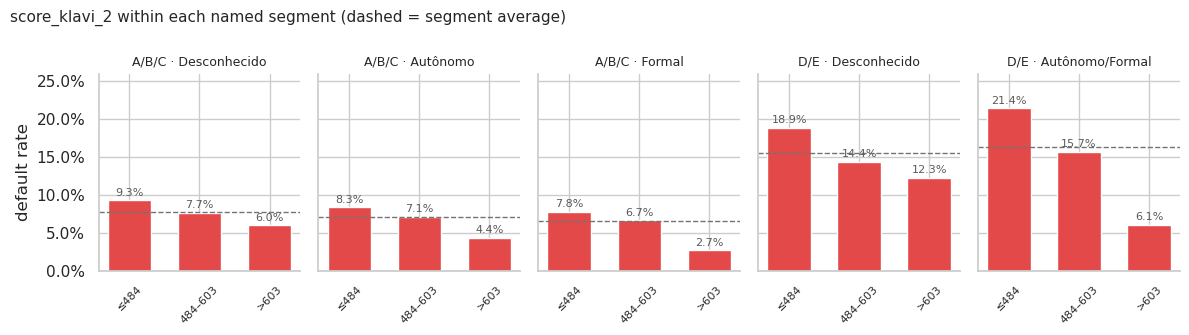

In [4]:
SCORE_BINS = [c for c in lab["score_bin"].cat.categories if c != "(missing)"]
fig, axes = plt.subplots(1, 5, figsize=(12, 3.4), sharey=True)
for ax, s in zip(axes, NAMED):
    d = lab[lab["segmento"] == s]
    r = pv_r.loc[s, SCORE_BINS]
    ax.bar(range(len(SCORE_BINS)), r, color=C_RISK, width=0.62)
    for i, br in enumerate(r):
        ax.text(i, br + 0.006, f"{br:.1%}", ha="center", fontsize=8, color="0.35")
    ax.axhline(d["OVER30M2"].mean(), color="0.45", ls="--", lw=1)
    ax.set_title(s, fontsize=9)
    ax.set_xticks(range(len(SCORE_BINS)),
                  [b.split(": ")[1] for b in SCORE_BINS], rotation=45, fontsize=8)
axes[0].set_ylim(0, 0.26)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("default rate")
fig.suptitle("score_klavi_2 within each named segment (dashed = segment average)",
             x=0.01, ha="left", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

**Key takeaway**: the score **orders risk end-to-end inside every named segment** — bottom vs
top bin: 9.3→6.0, 8.3→4.4, 7.8→2.7, 18.9→12.3 and **21.4→6.1%** in `D/E · Autônomo/Formal`,
where the gradient is steepest (3.5×): the score rescues a genuinely safe sub-population inside
the riskiest demographic cell — direct evidence for per-segment cutoffs over blanket segment
denial. With the score coarsened to **three monotone bins**, all five named cells now decline
cleanly bottom-to-top — the mid-scale wobble seen under the old four-bin split is gone (it was the
non-significant middle cut, thin-bin noise). In the `(missing)` segment only 113 labeled rows carry
a score: **no usable score axis there**.

## 3. The missing-score rule

Two distinct no-score populations need explicit paths:

**(a)** scoreless applicants *inside* named segments (~11% of named rows);

**(b)** the `(missing)` segment itself (no demographics, no score — 1.1% coverage, 3.0 §1).

In [5]:
named_lab = lab[lab["segmento"] != "(missing)"]
has_score = named_lab["score_bin"].eq("(missing)").map({True: "sem score", False: "com score"})
cmp = (named_lab.groupby(["segmento", has_score], observed=True)["OVER30M2"]
       .agg(n="size", bad_rate="mean").unstack())
cmp["bad_rate"] = (cmp["bad_rate"] * 100).round(1)
display(cmp)
print(f"(missing) segment baseline: "
      f"{lab.loc[lab['segmento'] == '(missing)', 'OVER30M2'].mean():.1%} "
      f"(n={int((lab['segmento'] == '(missing)').sum()):,})")

n            bad_rate          
score_bin             com score sem score com score sem score
segmento                                                     
A/B/C · Desconhecido       3863       455       7.9       6.8
A/B/C · Autônomo           3035       369       6.9       7.9
A/B/C · Formal             1615       195       6.3       8.2
D/E · Desconhecido         2017       246      15.5      15.9
D/E · Autônomo/Formal       446        77      16.6      14.3

(missing) segment baseline: 11.5% (n=11,830)


**Key takeaway → the rule**: within named segments, scoreless applicants default **at the
segment's own average** (deltas −2.3 to +1.9 pp, no consistent sign, n 77–455): score
availability is not adverse selection here. 

So — 

**(a)** scoreless in a named segment → treat at
the segment's baseline;

**(b)** the
`(missing)` segment → its own cell at 11.5% (between the A/B/C and D/E tiers): — incentivizing snapshot/open-finance consent converts unpriceable volume into the named cells.

## Key takeaways

- **Baseline validated**: segment ordering holds in 74/78 vintage cells, segment-mix PSI ≤ 0.027
  — the demographic structure is the stable part of the policy.
- **Cutoff axis validated**: score orders risk end-to-end in all 5 named cells; steepest inside
  `D/E · Autônomo/Formal` (21.4→6.1%) — per-segment cutoffs beat blanket denial.
- **Missing-score rule made explicit**: named-segment scoreless → segment baseline; `(missing)`
  segment → own cell (11.5%), appetite + data-acquisition lever.